In [1]:
from pathlib import Path
import cv2
import numpy as np
from tqdm.auto import tqdm

INPUT_DIR = Path("/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot_rim_256/Rims_256")               # ide tedd a sziluetteket
OUTLINE_DIR = INPUT_DIR / "outlines"     # körvonalak
BROKEN_DIR = INPUT_DIR / "broken"        # szakadozott körvonalak

LINE_THICKNESS = 2       # körvonal vastagsága (px)
N_GAPS = (4, 8)           # szakadások száma képenként: [min, max)
GAP_RADIUS = (5, 30)      # egy szakadás "sugara" px-ben: [min, max)
SEED = 42                 # None = minden futásnál más

EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
OUTLINE_DIR.mkdir(parents=True, exist_ok=True)
BROKEN_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)

/caa/Homes01/alaczko/Diploma/Diploma/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
def make_outline(img):
    _, mask = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY_INV)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    outline = np.full_like(img, 255)
    cv2.drawContours(outline, contours, -1, color=0, thickness=LINE_THICKNESS)
    return outline

images = sorted(p for p in INPUT_DIR.iterdir() if p.suffix.lower() in EXTENSIONS)

print(f"{len(images)} sziluett képet találtam a {INPUT_DIR} könyvtárban.")

for path in tqdm(images, desc="Körvonalak"):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        print(f"Kihagyva (nem olvasható): {path.name}")
        continue
    cv2.imwrite(str(OUTLINE_DIR / f"{path.stem}.png"), make_outline(img))

In [ ]:
def break_outline(outline):
    broken = outline.copy()
    ys, xs = np.nonzero(outline < 128)          # a vonal pixelei
    if len(xs) == 0:
        return broken
    for i in rng.choice(len(xs), rng.integers(*N_GAPS), replace=False):
        r = int(rng.integers(*GAP_RADIUS))
        cv2.circle(broken, (int(xs[i]), int(ys[i])), r, color=255, thickness=-1)
    return broken

outlines = sorted(OUTLINE_DIR.glob("*.png"))

for path in tqdm(outlines, desc="Szakadások"):
    outline = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    cv2.imwrite(str(BROKEN_DIR / path.name), break_outline(outline))

In [3]:
NOISY_DIR = INPUT_DIR / "noisy"          # szakadozott + zajos körvonalak
NOISY_DIR.mkdir(parents=True, exist_ok=True)

N_SPECKLES = (30, 60)      # apró zajpöttyök száma képenként: [min, max)
SPECKLE_RADIUS = (1, 3)    # egy pötty sugara px-ben: [min, max)
NEAR_LINE_PROB = 0.7       # ennyi eséllyel a vonal közelébe kerül egy pötty (különben bárhova)
NEAR_LINE_MAX_DIST = 20    # "közelség" px-ben, ha a vonal mellé kerül

N_DASHES = (0, 4)          # rövid vonalkák (pl. szkennelési csíkok) száma képenként: [min, max)
DASH_LENGTH = (6, 18)      # egy vonalka hossza px-ben: [min, max)
DASH_OFFSET = (5, 25)      # a vonalka milyen távol induljon a körvonaltól

def add_noise(outline):
    noisy = outline.copy()
    h, w = noisy.shape
    ys, xs = np.nonzero(outline < 128)   # a (törött) vonal pixelei, ehhez képest helyezzük el a zajt
    has_line = len(xs) > 0

    for _ in range(rng.integers(*N_SPECKLES)):
        if has_line and rng.random() < NEAR_LINE_PROB:
            i = rng.integers(len(xs))
            cx = int(xs[i]) + int(rng.integers(-NEAR_LINE_MAX_DIST, NEAR_LINE_MAX_DIST + 1))
            cy = int(ys[i]) + int(rng.integers(-NEAR_LINE_MAX_DIST, NEAR_LINE_MAX_DIST + 1))
        else:
            cx, cy = int(rng.integers(0, w)), int(rng.integers(0, h))
        cx, cy = int(np.clip(cx, 0, w - 1)), int(np.clip(cy, 0, h - 1))
        r = int(rng.integers(*SPECKLE_RADIUS))
        cv2.circle(noisy, (cx, cy), r, color=0, thickness=-1)

    for _ in range(rng.integers(*N_DASHES)):
        if not has_line:
            break
        i = rng.integers(len(xs))
        angle = rng.uniform(0, 2 * np.pi)
        offset = rng.integers(*DASH_OFFSET)
        ox = int(xs[i] + np.cos(angle) * offset)
        oy = int(ys[i] + np.sin(angle) * offset)
        length = int(rng.integers(*DASH_LENGTH))
        dx, dy = np.cos(angle) * length / 2, np.sin(angle) * length / 2
        p1 = (int(np.clip(ox - dx, 0, w - 1)), int(np.clip(oy - dy, 0, h - 1)))
        p2 = (int(np.clip(ox + dx, 0, w - 1)), int(np.clip(oy + dy, 0, h - 1)))
        cv2.line(noisy, p1, p2, color=0, thickness=1)

    return noisy

broken_files = sorted(BROKEN_DIR.glob("*.png"))

for path in tqdm(broken_files, desc="Zajosítás"):
    broken = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    cv2.imwrite(str(NOISY_DIR / path.name), add_noise(broken))

Zajosítás: 100%|██████████| 4620/4620 [14:39<00:00,  5.26it/s]


In [ ]:
import matplotlib.pyplot as plt

# ---- Realisztikusabb zaj: pöttyök a vonal mellett + helyi megvastagodás (főleg görbületeknél) ----

TEST_NAME = None           # melyik képen teszteljünk (pl. "abc.png"); None = az első a BROKEN_DIR-ből
TEST_SEED = None           # fix seed a teszthez (pl. 0), hogy ugyanazt kapd újrafuttatáskor; None = mindig más

# Megvastagodás
N_THICK = (4, 10)          # megvastagodott szakaszok száma képenként: [min, max)
THICK_LENGTH = (8, 30)     # egy szakasz hossza a vonal mentén (px): [min, max)
THICK_EXTRA = (1.0, 3.5)   # ennyivel vastagabb a szakasz közepe (sugár px-ben): [min, max)
THICK_ONE_SIDED = 0.6      # ennyi eséllyel csak az egyik oldalra "hízik" a vonal
CURV_WINDOW = 6            # görbület számításának ablaka (pontszám a kontúr mentén)
CURV_POWER = 2.0           # mennyire preferálja a görbületeket (0 = egyenletes, nagyobb = erősebben)
END_CAP_ANGLE = 2.4        # efölötti irányváltás (radián) a szakadások végét jelzi (a kontúr ott visszafordul), azt kihagyjuk

# Kis tüskék / dudorok közvetlenül a vonalon
N_BURRS = (10, 30)         # száma képenként: [min, max)
BURR_RADIUS = (1, 3)       # sugár px-ben: [min, max)

# Pöttyök
N_DOTS = (30, 80)          # pöttyök száma képenként: [min, max)
DOT_DIST_SCALE = 3.0       # a vonaltól mért távolság exponenciális eloszlású, ennyi az átlaga (px)
DOT_RADIUS_PROBS = (0.6, 0.35, 0.05)  # 0 / 1 / 2 px sugarú pötty esélye (0 = egyetlen pixel)
FAR_DOT_PROB = 0.05        # ennyi eséllyel kerül egy pötty bárhova a képen


def line_contours(img):
    mask = (img < 128).astype(np.uint8)
    contours, _ = cv2.findContours(mask, cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)
    return [c[:, 0, :].astype(np.float32) for c in contours if len(c) > 2 * CURV_WINDOW + 1]


def contour_curvature(pts):
    # irányváltás szöge a pont előtti és utáni CURV_WINDOW lépés között (0 = egyenes, pi = visszafordul)
    k = CURV_WINDOW
    v1 = pts - np.roll(pts, k, axis=0)
    v2 = np.roll(pts, -k, axis=0) - pts
    cos = (v1 * v2).sum(1) / (np.linalg.norm(v1, axis=1) * np.linalg.norm(v2, axis=1) + 1e-6)
    return np.arccos(np.clip(cos, -1, 1))


def thicken(img, contours):
    if not contours:
        return
    # minden kontúrpont kap egy súlyt a görbülete alapján, ebből húzzuk a szakaszok középpontját
    pool = [(ci, i) for ci, c in enumerate(contours) for i in range(len(c))]
    weights = []
    for c in contours:
        curv = contour_curvature(c)
        w = curv ** CURV_POWER + 0.02
        cap = curv > END_CAP_ANGLE
        for s in range(-2 * CURV_WINDOW, 2 * CURV_WINDOW + 1):   # a szakadásvég környékét is kihagyjuk
            w[np.roll(cap, s)] = 0
        weights.append(w)
    weights = np.concatenate(weights)
    if weights.sum() == 0:
        return
    weights /= weights.sum()

    for idx in rng.choice(len(pool), int(rng.integers(*N_THICK)), p=weights):
        ci, center = pool[idx]
        pts = contours[ci]
        n = len(pts)
        half = int(rng.integers(*THICK_LENGTH)) // 2
        extra = rng.uniform(*THICK_EXTRA)
        one_sided = rng.random() < THICK_ONE_SIDED
        side = rng.choice([-1, 1])
        for j in range(-half, half + 1):
            i = (center + j) % n
            t = 1 - abs(j) / (half + 1)                         # 1 a közepén, 0 a széleken
            r = extra * np.sin(t * np.pi / 2) ** 0.8            # sima, orsó alakú profil
            r *= rng.uniform(0.8, 1.2)                          # kis egyenetlenség
            p = pts[i]
            if one_sided:
                tangent = pts[(i + 1) % n] - pts[(i - 1) % n]
                normal = np.array([-tangent[1], tangent[0]]) / (np.linalg.norm(tangent) + 1e-6)
                p = p + side * normal * r * 0.6
            cv2.circle(img, (int(round(p[0])), int(round(p[1]))), int(round(r)), color=0, thickness=-1)


def add_burrs(img, xs, ys):
    for _ in range(int(rng.integers(*N_BURRS))):
        i = rng.integers(len(xs))
        cx = int(xs[i] + rng.integers(-1, 2))
        cy = int(ys[i] + rng.integers(-1, 2))
        cv2.circle(img, (cx, cy), int(rng.integers(*BURR_RADIUS)), color=0, thickness=-1)


def add_dots(img, xs, ys):
    h, w = img.shape
    for _ in range(int(rng.integers(*N_DOTS))):
        if rng.random() < FAR_DOT_PROB:
            cx, cy = int(rng.integers(0, w)), int(rng.integers(0, h))
        else:
            i = rng.integers(len(xs))
            angle = rng.uniform(0, 2 * np.pi)
            dist = 1 + rng.exponential(DOT_DIST_SCALE)
            cx = int(round(xs[i] + np.cos(angle) * dist))
            cy = int(round(ys[i] + np.sin(angle) * dist))
        if 0 <= cx < w and 0 <= cy < h:
            r = int(rng.choice(len(DOT_RADIUS_PROBS), p=DOT_RADIUS_PROBS))
            cv2.circle(img, (cx, cy), r, color=0, thickness=-1)


def add_noise_v2(outline):
    noisy = outline.copy()
    ys, xs = np.nonzero(outline < 128)
    if len(xs) == 0:
        return noisy
    thicken(noisy, line_contours(outline))
    add_burrs(noisy, xs, ys)
    add_dots(noisy, xs, ys)
    return noisy


# ---- Teszt egy képen ----
if TEST_SEED is not None:
    rng = np.random.default_rng(TEST_SEED)

test_path = BROKEN_DIR / TEST_NAME if TEST_NAME else sorted(BROKEN_DIR.glob("*.png"))[0]
broken = cv2.imread(str(test_path), cv2.IMREAD_GRAYSCALE)
noisy = add_noise_v2(broken)

diff = cv2.cvtColor(broken, cv2.COLOR_GRAY2RGB)
diff[(noisy < 128) & (broken >= 128)] = (220, 0, 0)    # pirossal az újonnan hozzáadott pixelek

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (im, title) in zip(axes, [(broken, "Szakadozott (bemenet)"), (noisy, "Zajos"), (diff, "Hozzáadott zaj (piros)")]):
    ax.imshow(im, cmap="gray" if im.ndim == 2 else None, interpolation="nearest")
    ax.set_title(title); ax.axis("off")
plt.suptitle(test_path.name)
plt.tight_layout()
plt.show()

In [ ]:
broken_files = sorted(BROKEN_DIR.glob("*.png"))

for path in tqdm(broken_files, desc="Zajosítás"):
    broken = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    cv2.imwrite(str(NOISY_DIR / path.name), add_noise_v2(broken))

In [ ]:
import matplotlib.pyplot as plt

name = outlines[0].name   # melyik képet nézzük
original = next(p for p in images if p.stem == Path(name).stem)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (p, title) in zip(axes, [(original, "Eredeti"),
                                 (OUTLINE_DIR / name, "Körvonal"),
                                 (BROKEN_DIR / name, "Szakadozott")]):
    ax.imshow(cv2.imread(str(p), cv2.IMREAD_GRAYSCALE), cmap="gray")
    ax.set_title(title); ax.axis("off")
plt.show()

In [61]:
from pathlib import Path
import random
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

TRAIN_INPUT_DIR = Path("/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot_rim_256/Rims_256/noisy")      # bemenet: törött körvonalak
OUTLINE_DIR = Path("/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot_rim_256/Rims_256/outlines")   # ground truth: hibátlan körvonalak
IMG_SIZE = 256            # 16-tal osztható legyen
BATCH_SIZE = 64
EPOCHS = 100
LR = 1e-3
VAL_RATIO = 0.2
MODEL_PATH = "unet_outline_fix.pt"

torch.backends.cudnn.benchmark = True

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Eszköz:", device)
random.seed(42); torch.manual_seed(42)

Eszköz: cuda


In [62]:
def load(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    return (img < 128).astype(np.float32)     # vonal = 1, háttér = 0

class OutlineDataset(Dataset):
    def __init__(self, files, augment=False):
        self.augment = augment
        self.files = files
        self.X = np.stack([load(f) for f in tqdm(files, desc="Betöltés")])
        self.Y = np.stack([load(OUTLINE_DIR / f.name) for f in files])
    def __len__(self):
        return len(self.X)
    def __getitem__(self, i):
        x, y = self.X[i], self.Y[i]
        if self.augment:
            k = random.randint(0, 3)
            x, y = np.rot90(x, k), np.rot90(y, k)
            if random.random() < 0.5:
                x, y = np.fliplr(x), np.fliplr(y)
        return torch.from_numpy(x.copy())[None], torch.from_numpy(y.copy())[None]

files = sorted(p for p in TRAIN_INPUT_DIR.glob("*.png") if (OUTLINE_DIR / p.name).exists())
random.shuffle(files)
n_val = max(1, int(len(files) * VAL_RATIO))
train_ds = OutlineDataset(files[n_val:], augment=True)
val_ds = OutlineDataset(files[:n_val])
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=BATCH_SIZE)
print(f"Train: {len(train_ds)}, val: {len(val_ds)}")

def show_training_samples(ds, n=3):
    """Ellenőrzés tanítás előtt: n véletlen bemenet + ground truth pár a datasetből, és hogy miben térnek el."""
    import matplotlib.pyplot as plt
    print(f"Bemenet: {TRAIN_INPUT_DIR}\nGround truth: {OUTLINE_DIR}")
    idx = random.sample(range(len(ds)), n)
    fig, axes = plt.subplots(n, 3, figsize=(15, 5 * n), squeeze=False)
    for row, i in zip(axes, idx):
        x, y = ds.X[i] > 0.5, ds.Y[i] > 0.5
        diff = np.ones((*x.shape, 3))
        diff[x & y] = (0.6, 0.6, 0.6)        # szürke: mindkettőben vonal
        diff[x & ~y] = (0.85, 0, 0)          # piros: csak a bemenetben (zaj, vastagodás)
        diff[~x & y] = (0, 0.6, 0)           # zöld: csak a GT-ben (szakadás)
        for ax, (im, title) in zip(row, [(1 - x, f"Bemenet: {ds.files[i].name}"),
                                         (1 - y, "Ground truth"),
                                         (diff, f"Eltérés: {(x & ~y).sum()} zaj px, {(~x & y).sum()} szakadás px")]):
            ax.imshow(im, cmap="gray" if im.ndim == 2 else None, interpolation="nearest")
            ax.set_title(title, fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.show()
    n_same = sum(np.array_equal(ds.X[i], ds.Y[i]) for i in range(len(ds)))
    if n_same:
        print(f"FIGYELEM: {n_same} képpárnál a bemenet és a GT azonos!")

Betöltés:   0%|          | 0/3696 [00:00<?, ?it/s]

Betöltés: 100%|██████████| 3696/3696 [00:22<00:00, 162.58it/s]


KeyboardInterrupt: 

In [6]:
def block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
    )

class UNet(nn.Module):
    def __init__(self, ch=(32, 64, 128, 256)):
        super().__init__()
        self.downs = nn.ModuleList()
        cin = 1
        for c in ch:
            self.downs.append(block(cin, c)); cin = c
        self.bottleneck = block(ch[-1], ch[-1] * 2)
        self.ups = nn.ModuleList()
        self.up_blocks = nn.ModuleList()
        cin = ch[-1] * 2
        for c in reversed(ch):
            self.ups.append(nn.ConvTranspose2d(cin, c, 2, stride=2))
            self.up_blocks.append(block(c * 2, c)); cin = c
        self.out = nn.Conv2d(ch[0], 1, 1)

    def forward(self, x):
        skips = []
        for d in self.downs:
            x = d(x); skips.append(x); x = F.max_pool2d(x, 2)
        x = self.bottleneck(x)
        for up, blk, s in zip(self.ups, self.up_blocks, reversed(skips)):
            x = blk(torch.cat([up(x), s], dim=1))
        return self.out(x)

def dice_loss(logits, target, eps=1.0):
    p = torch.sigmoid(logits)
    inter = (p * target).sum(dim=(1, 2, 3))
    union = p.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return 1 - ((2 * inter + eps) / (union + eps)).mean()

def loss_fn(logits, target):
    return F.binary_cross_entropy_with_logits(logits, target) + dice_loss(logits, target)

In [7]:
model = UNet().to(device)

In [4]:
show_training_samples(train_ds)

model = UNet().to(device)
opt = torch.optim.Adam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=5, min_lr=1e-6)
scaler = torch.amp.GradScaler(enabled=(device == "cuda"))
best_val = float("inf")

ES_PATIENCE = 15   # ES: ennyi javulás nélküli epoch után leáll
bad_epochs = 0     # ES

for epoch in range(1, EPOCHS + 1):
    model.train(); train_loss = 0
    for x, y in tqdm(train_dl, desc=f"Epoch {epoch}/{EPOCHS}", leave=False):
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type=device, enabled=(device == "cuda")):
            loss = loss_fn(model(x), y)
        opt.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        train_loss += loss.item() * len(x)
    train_loss /= len(train_ds)

    model.eval(); val_loss = 0
    with torch.no_grad():
        for x, y in val_dl:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device_type=device, enabled=(device == "cuda")):
                val_loss += loss_fn(model(x), y).item() * len(x)
    val_loss /= len(val_ds)

    lr_before = opt.param_groups[0]["lr"]     # adaptive LR: elmentjük lépés előtt
    sched.step(val_loss)
    lr_after = opt.param_groups[0]["lr"]

    flag = ""
    if val_loss < best_val:
        best_val = val_loss
        bad_epochs = 0                                          # ES: javult, számláló nullázása
        torch.save(model.state_dict(), MODEL_PATH); flag = "  ✓ mentve"
    else:
        bad_epochs += 1                                         # ES
    lr_note = f"  (lr csökkentve: {lr_before:.2e} -> {lr_after:.2e})" if lr_after < lr_before else ""
    print(f"Epoch {epoch}: train {train_loss:.4f}, val {val_loss:.4f}, lr {lr_after:.2e}{flag}{lr_note}")

    if bad_epochs >= ES_PATIENCE:                               # ES
        print(f"Early stopping: {ES_PATIENCE} epoch óta nincs javulás.")
        break

Epoch 1: train 1.1595, val 0.9841, lr 1.00e-03  ✓ mentve


Epoch 2: train 0.8485, val 0.7164, lr 1.00e-03  ✓ mentve


Epoch 3: train 0.5587, val 0.6682, lr 1.00e-03  ✓ mentve


Epoch 4: train 0.3294, val 0.2666, lr 1.00e-03  ✓ mentve


Epoch 5: train 0.2093, val 0.1746, lr 1.00e-03  ✓ mentve


Epoch 6: train 0.1546, val 0.1365, lr 1.00e-03  ✓ mentve


... (90 outputs left out)

Epoch 97: train 0.0461, val 0.0588, lr 1.56e-05  (lr csökkentve: 3.13e-05 -> 1.56e-05)


Epoch 98: train 0.0459, val 0.0587, lr 1.56e-05


Epoch 99: train 0.0459, val 0.0588, lr 1.56e-05


Epoch 100: train 0.0458, val 0.0589, lr 1.56e-05
Early stopping: 15 epoch óta nincs javulás.


In [ ]:
import sys
from einops import rearrange
from vit_pytorch import ViT

DOCENTR_DIR = Path("/caa/Homes01/alaczko/Diploma/Diploma/external/DocEnTr")
sys.path.insert(0, str(DOCENTR_DIR))
from models.binae import BinModel
import vit_pytorch.vit as _vit

def _sdpa_attention(self, x):
    # ugyanaz a számítás, mint az eredeti vit_pytorch Attention, csak memóriatakarékos (flash) attentionnel
    q, k, v = (rearrange(t, "b n (h d) -> b h n d", h=self.heads) for t in self.to_qkv(x).chunk(3, dim=-1))
    out = F.scaled_dot_product_attention(q, k, v, scale=self.scale)
    return self.to_out(rearrange(out, "b h n d -> b n (h d)"))

_vit.Attention.forward = _sdpa_attention

DOCENTR_WEIGHTS = DOCENTR_DIR / "weights" / "model_8_2018_base.pt"   # H-DIBCO 2018, base, 8x8 patch
PATCH = 8

class DocEnTrFix(nn.Module):
    """A UNet helyére tehető: bemenet (B,1,H,W) vonalmaszk (vonal = 1), kimenet (B,1,H,W) logit (vonal = pozitív)."""
    MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)   # az eredeti DocEnTr ImageNet-normalizálása
    STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

    def __init__(self, weights=DOCENTR_WEIGHTS):
        super().__init__()
        vit = ViT(image_size=IMG_SIZE, patch_size=PATCH, num_classes=1000,
                  dim=768, depth=6, heads=8, mlp_dim=2048)               # "base" beállítás
        self.net = BinModel(encoder=vit, decoder_dim=768, decoder_depth=6, decoder_heads=8)
        if weights is not None:
            self.net.load_state_dict(torch.load(weights, map_location="cpu"))
        # a DocEnTr "fehérséget" ad vissza (háttér ~1, tinta ~0) -> ezt fordítjuk át vonal-logittá
        self.scale = nn.Parameter(torch.tensor(10.0))
        self.register_buffer("mean", self.MEAN)
        self.register_buffer("std", self.STD)

    def forward(self, x):
        img = (1 - x).repeat(1, 3, 1, 1)                  # fehér háttér, fekete vonal, 3 csatorna
        img = (img - self.mean) / self.std
        n = self.net
        tokens = n.patch_to_emb(n.to_patch(img))
        tokens = tokens + n.encoder.pos_embedding[:, 1:tokens.shape[1] + 1]
        out = n.to_pixels(n.decoder(n.enc_to_dec(n.encoder.transformer(tokens))))
        out = rearrange(out, "b (h w) (p1 p2 c) -> b c (h p1) (w p2)",
                        p1=PATCH, p2=PATCH, h=x.shape[-2] // PATCH)
        whiteness = out.mean(1, keepdim=True)
        return self.scale * (0.5 - whiteness)

In [ ]:
show_training_samples(train_ds)

MODEL_PATH = "docentr_outline_fix.pt"
DOCENTR_BATCH = 32        # batch 32 ~11 GB GPU memória; 64 már ~20 GB
DOCENTR_LR = 1e-4         # ViT fine-tune-hoz kisebb lr kell, mint a UNet-hez

train_dl = DataLoader(train_ds, batch_size=DOCENTR_BATCH, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=DOCENTR_BATCH)

model = DocEnTrFix().to(device)
opt = torch.optim.AdamW(model.parameters(), lr=DOCENTR_LR, weight_decay=0.05)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=5, min_lr=1e-6)
scaler = torch.amp.GradScaler(enabled=(device == "cuda"))
best_val = float("inf")

ES_PATIENCE = 15   # ES: ennyi javulás nélküli epoch után leáll
bad_epochs = 0     # ES

for epoch in range(1, EPOCHS + 1):
    model.train(); train_loss = 0
    for x, y in tqdm(train_dl, desc=f"Epoch {epoch}/{EPOCHS}", leave=False):
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type=device, enabled=(device == "cuda")):
            loss = loss_fn(model(x), y)
        opt.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        train_loss += loss.item() * len(x)
    train_loss /= len(train_ds)

    model.eval(); val_loss = 0
    with torch.no_grad():
        for x, y in val_dl:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device_type=device, enabled=(device == "cuda")):
                val_loss += loss_fn(model(x), y).item() * len(x)
    val_loss /= len(val_ds)

    lr_before = opt.param_groups[0]["lr"]
    sched.step(val_loss)
    lr_after = opt.param_groups[0]["lr"]

    flag = ""
    if val_loss < best_val:
        best_val = val_loss
        bad_epochs = 0
        torch.save(model.state_dict(), MODEL_PATH); flag = "  ✓ mentve"
    else:
        bad_epochs += 1
    lr_note = f"  (lr csökkentve: {lr_before:.2e} -> {lr_after:.2e})" if lr_after < lr_before else ""
    print(f"Epoch {epoch}: train {train_loss:.4f}, val {val_loss:.4f}, lr {lr_after:.2e}{flag}{lr_note}")

    if bad_epochs >= ES_PATIENCE:
        print(f"Early stopping: {ES_PATIENCE} epoch óta nincs javulás.")
        break

In [58]:
import matplotlib.pyplot as plt
import random

TEST_DIR = Path("/caa/Homes01/alaczko/Diploma/Diploma/data/pipeline/run_2909___2/repaired")   # ide a javítandó képek
FIXED_DIR = Path("/caa/Homes01/alaczko/Diploma/Diploma/data/pipeline/run_2909___2/fixed")     # ide kerülnek a javított képek
DEBUG_DIR = FIXED_DIR.parent / "fixed_debug"                                                  # ide a before/after összehasonlítások
FIXED_DIR.mkdir(exist_ok=True)
DEBUG_DIR.mkdir(exist_ok=True)

SAVE_DEBUG = True      # mentsen-e debug képeket
N_SHOW = 4             # ennyi véletlen példát jelenít meg a notebookban a végén
THRESHOLD = 0.5        # efölötti valószínűségnél vonalnak tekintjük a pixelt

model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()

def fix_image(path):
    orig = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    x = torch.from_numpy(load(path))[None, None].to(device)
    with torch.no_grad():
        prob = torch.sigmoid(model(x))[0, 0].cpu().numpy()
    prob = cv2.resize(prob, (orig.shape[1], orig.shape[0]), interpolation=cv2.INTER_LINEAR)
    fixed = np.where(prob > THRESHOLD, 0, 255).astype(np.uint8)
    return orig, prob, fixed

def label(img, text):
    img = img.copy()
    cv2.rectangle(img, (0, 0), (img.shape[1], 22), (255, 255, 255), thickness=-1)
    cv2.putText(img, text, (5, 16), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1, cv2.LINE_AA)
    return img

def make_debug(orig, prob, fixed):
    orig_line = orig < 128
    fixed_line = fixed < 128
    removed = orig_line & ~fixed_line      # eredetin vonal volt, javítotton nincs -> eltávolított zaj
    added = ~orig_line & fixed_line        # eredetin nem volt, javítotton van -> pótolt szakadás

    orig_bgr = cv2.cvtColor(orig, cv2.COLOR_GRAY2BGR)
    fixed_bgr = cv2.cvtColor(fixed, cv2.COLOR_GRAY2BGR)
    prob_bgr = cv2.applyColorMap((np.clip(prob, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_JET)

    diff = cv2.cvtColor(orig, cv2.COLOR_GRAY2BGR)
    diff = (255 - (255 - diff) * 0.3).astype(np.uint8)   # halvány eredeti háttérnek
    diff[removed] = (0, 0, 255)                          # piros (BGR)
    diff[added] = (0, 200, 0)                            # zöld

    sep = np.full((orig.shape[0], 4, 3), 128, dtype=np.uint8)
    panels = [
        label(orig_bgr, "eredeti"),
        label(prob_bgr, "valoszinuseg"),
        label(fixed_bgr, "javitott"),
        label(diff, f"-{removed.sum()} / +{added.sum()} px"),
    ]
    row = panels[0]
    for p in panels[1:]:
        row = np.hstack([row, sep, p])
    return row, removed.sum(), added.sum()

paths = sorted(TEST_DIR.glob("*.jpg"))
stats = []

for path in tqdm(paths, desc="Javítás"):
    orig, prob, fixed = fix_image(path)
    cv2.imwrite(str(FIXED_DIR / path.name), fixed)
    if SAVE_DEBUG:
        debug, n_removed, n_added = make_debug(orig, prob, fixed)
        cv2.imwrite(str(DEBUG_DIR / f"{path.stem}.png"), debug)   # png, hogy ne legyen jpg műtermék
        stats.append((path.name, n_removed, n_added))

if stats:
    stats.sort(key=lambda s: s[1] + s[2], reverse=True)
    print("Legtöbbet változott képek (eltávolított / hozzáadott px):")
    for name, r, a in stats[:10]:
        print(f"  {name}: -{r} / +{a}")

# Néhány véletlen példa megjelenítése
for path in random.sample(paths, min(N_SHOW, len(paths))):
    debug, _, _ = make_debug(*fix_image(path))
    plt.figure(figsize=(18, 5))
    plt.imshow(cv2.cvtColor(debug, cv2.COLOR_BGR2RGB))
    plt.title(path.name)
    plt.axis("off")
    plt.show()

Javítás:  86%|████████▌ | 5300/6171 [07:57<01:18, 11.10it/s]


KeyboardInterrupt: 

In [ ]:
import random
n = 40
sample_files = random.sample(val_ds.files, n)
fig, axes = plt.subplots(n, 3, figsize=(15, 5 * n))
for row, f in zip(axes, sample_files):
    name = f.name
    for ax, (p, title) in zip(row, [(TEST_DIR / name, "broken"),
                                     (FIXED_DIR / name, "fixed (U-Net)"),
                                     (OUTLINE_DIR / name, "Ground truth")]):
        ax.imshow(cv2.imread(str(p), cv2.IMREAD_GRAYSCALE), cmap="gray")
        ax.set_title(title)
        ax.axis("off")
plt.tight_layout()
plt.show()

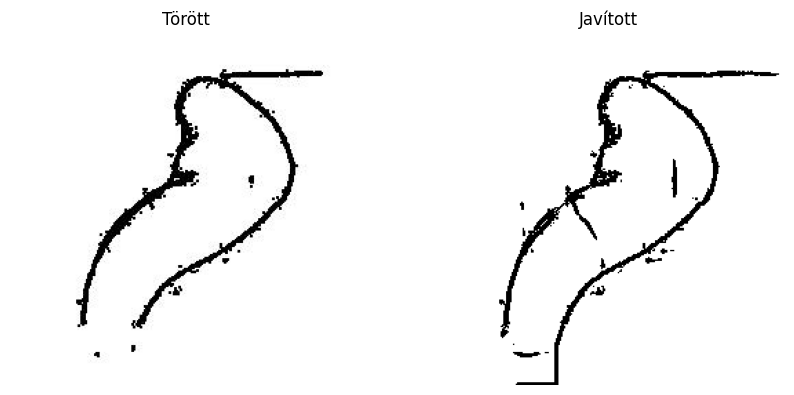

In [6]:
import matplotlib.pyplot as plt

IMG_PATH = Path("/caa/Homes01/alaczko/Diploma/Diploma/data/pipeline/run_2909___2/repaired/00_Selection ML__1976_Schedivy Zivilstadt GB_Sektoren 1-2 bis 21-22__Sektor 1-2__027.jpg")   # a javítandó kép

# Modell betöltése (ha még nincs betöltve)
model = UNet().to(device)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()

# Javítás
orig = cv2.imread(str(IMG_PATH), cv2.IMREAD_GRAYSCALE)
x = torch.from_numpy(load(IMG_PATH))[None, None].to(device)
with torch.no_grad():
    prob = torch.sigmoid(model(x))[0, 0].cpu().numpy()
prob = cv2.resize(prob, (orig.shape[1], orig.shape[0]), interpolation=cv2.INTER_LINEAR)
fixed = np.where(prob > 0.5, 0, 255).astype(np.uint8)

# Plot
panels = [(orig, "Törött"), (fixed, "Javított")]
gt_path = OUTLINE_DIR / IMG_PATH.name
if gt_path.exists():
    panels.append((cv2.imread(str(gt_path), cv2.IMREAD_GRAYSCALE), "Ground truth"))

fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 5))
for ax, (im, title) in zip(axes, panels):
    ax.imshow(im, cmap="gray"); ax.set_title(title); ax.axis("off")
plt.show()